## Problem Assignment: Numerical Schemes for the 1D Linear Advection Equation

### 1\. Problem Definition

You are tasked with numerically solving the 1D linear advection equation:

$$
\frac{\partial u}{\partial t} + \frac{\partial u}{\partial x} = 0
$$

This equation describes a wave $u(x, t)$ traveling to the right with a constant speed $c=1$.

* **Domain:** A periodic spatial domain, $x \in [0, 25.0]$.
* **Initial Condition ($t=0$):** The solution starts as a sum of two pulses:
$u(x, 0) = \exp(-20.0(x - 2)^2) + \exp(-(x - 5)^2)$
* **Exact Solution:** For this problem, the exact solution is the initial shape simply "advecting" or moving to the right. It is given by $u(x, t) = u(x-t, 0)$.

We will use the following Python function to represent the exact solution at any given time `t`:

```python
import numpy as np
u_true = lambda x, t: np.exp(-20.0 * ((x - t) - 2.0)**2) + np.exp(-((x - t) - 5.0)**2)
```

-----



### 2\. Numerical Setup

All your simulations must use the following discretization parameters:

* **Grid Points:** `m = 501`
* **Spatial Grid:** `x = np.linspace(0, 25.0, m)`
* **Grid Spacing:** $\Delta x = 25.0 / (m - 1)$
* **Final Time:** `t_final = 17.0`
* **CFL Number:** $\nu = 0.8$ (Note: $\nu = c \frac{\Delta t}{\Delta x}$, and since $c=1$, $\nu = \frac{\Delta t}{\Delta x}$)
* **Time Step:** $\Delta t = \nu \cdot \Delta x$

-----



### 3\. Your Task: Implement and Compare

Your main task is to implement **five** different finite difference schemes to solve this problem. For each scheme, you will write a time-stepping loop that starts with the initial condition `U = u_true(x, 0)` and runs until `t = t_final`.

**Crucial:** You must correctly implement the **periodic boundary conditions** for each scheme. This means that for a grid point $U_i$, its right neighbor $U_{i+1}$ and left neighbor $U_{i-1}$ must "wrap around" at the boundaries.

* For $i=0$ (the first point), the left neighbor is $U_{m-1}$ (the last point).
* For $i=m-1$ (the last point), the right neighbor is $U_0$ (the first point).

Implement the following five methods (where $\nu = \Delta t / \Delta x$):

1.  **FTCS (Forward-Euler, Central-Space):**
2.  **Lax-Friedrichs:**
3.  **Upwind (First-Order):**
4.  **Lax-Wendroff:**
5.  **Beam-Warming:** 

-----



### 4\. Deliverables

You will submit your Jupyter Notebook as a pdf that completes the following:

1.  **Code:** A single script containing:

      * The setup (imports, parameters, initial condition).
      * A separate simulation loop for **each of the five methods**.
      * Store the final solution `U` from each method in a clearly named variable (e.g., `U_fe`, `U_lax_friedrichs`, etc.).

2.  **Plot:** A single, clear plot that visualizes the results at $t=17.0$. The plot must include:

      * The **exact solution** `u_true(x, t_final)` plotted as a solid black line (`'k'`).
      * The numerical results from **all five methods**. Plot each with a different style (e.g., `'ro'`, `'b--'`, `'g.'`, etc.) so they are distinguishable.
      * A clear **legend** identifying which line/marker corresponds to which method.
      * The plot limits set to zoom in on the solution:
          * `axes.set_xlim((15.0, 25.0))`
          * `axes.set_ylim((-0.1, 1.1))`

3.  **Analysis (Written):** In comments in your script or in a notebook markdown cell, answer the following questions:

      * **Stability:** Which (if any) methods failed to produce a stable solution? Based on what you know about numerical methods, why was this expected?
      * **Diffusion & Dispersion:** Compare the "good" solutions to the exact solution.
          * Which methods appear overly **diffusive** (smeared out)?
          * Which methods exhibit **dispersion** (spurious oscillations or "wiggles") near the sharp pulses?
      * **Conclusion:** Briefly state which method you think performed best and why.

-----



### 5\. Starter Code Template

You can use this template to get started. Your job is to fill in the `... # IMPLEMENT ...` sections.


In [141]:
import numpy as np
import matplotlib.pyplot as plt


In [142]:

# --- 1. Problem Definition ---
u_true = lambda x, t: np.exp(-20.0 * ((x - t) - 2.0)**2) + np.exp(-((x - t) - 5.0)**2)


In [143]:

# --- 2. Numerical Setup ---
m = 501
x = np.linspace(0, 25.0, m)
delta_x = 25.0 / (m - 1)
nu = 0.8 # This is our nu = delta_t / delta_x
delta_t = nu * delta_x
t = 0.0
t_final = 17.0


Forward Euler following Forward derivative in Time and Centered in Space

In [144]:

# Method 1: FE
U_fe = u_true(x, 0)
U_new = np.empty(U_fe.shape)
t = 0.0

while t < t_final:
    # ... IMPLEMENT FTCS loop here ...
    # FTCS = Forward Time, Centered Space (approx numericas usadas para las derivadas)
    # Ecuaciones interiores:
    U_new[1:-1] = U_fe[1:-1] - (nu/2)*(U_fe[2:] - U_fe[:-2]) # (En j+1) - (En j-1)
    
    # BCs periódicas:
    U_new[0] = U_fe[0] - (nu/2)*(U_fe[1] - U_fe[-1]) 
    U_new[-1] = U_fe[-1] - (nu/2)*(U_fe[0] - U_fe[-2])
    
    U_fe = U_new.copy()
    t += delta_t


Lax-Friedrichs

In [145]:

# Method 2: Lax-Friedrichs
U_lax_friedrichs = u_true(x, 0)
U_new = np.empty(U_lax_friedrichs.shape) # En vd no haría falta inicializar, pq la forma de todos es la misma
t = 0.0

while t < t_final:
    # ... IMPLEMENT Lax-Friedrichs loop here ...
    # This is the one from your example
    U_new[0] = (0.5 * (U_lax_friedrichs[1] + U_lax_friedrichs[-1])
                - nu / 2.0 * (U_lax_friedrichs[1] - U_lax_friedrichs[-1])) # -1 aparece por BC periódica
    
    U_new[1:-1] = (0.5 * (U_lax_friedrichs[2:] + U_lax_friedrichs[:-2]) 
                   - nu / 2.0 * (U_lax_friedrichs[2:] - U_lax_friedrichs[:-2]))
    
    U_new[-1] = (0.5 * (U_lax_friedrichs[0] + U_lax_friedrichs[-2]) 
                 - nu / 2.0 * (U_lax_friedrichs[0] - U_lax_friedrichs[-2])) # 0 aparece por BC periódica
    
    U_lax_friedrichs = U_new.copy()
    t += delta_t


Upwind

In [146]:

# Method 3: Upwind
U_upwind = u_true(x, 0)
U_new = np.empty(U_upwind.shape)
t = 0.0
while t < t_final:
    # ... IMPLEMENT Upwind loop here ...
    U_new[1:] = U_upwind[1:] - nu * (U_upwind[1:] - U_upwind[:-1] )
    # BCs periodicas (solo afecta al punto inicial pq utilizamos el de la izquierda por ser a > 0):
    U_new[0] = U_upwind[0] - nu * (U_upwind[0] - U_upwind[-1] )
    
    U_upwind = U_new.copy()
    t += delta_t


Lax-Wendroff

In [147]:

# Method 4: Lax-Wendroff
U_lax_wendroff = u_true(x, 0)
U_new = np.empty(U_lax_wendroff.shape)
t = 0.0
while t < t_final:
    # ... IMPLEMENT Lax-Wendroff loop here ...
    
    U_new[1:-1] = (U_lax_wendroff[1:-1] - (nu/2)*(U_lax_wendroff[2:] - U_lax_wendroff[:-2]) # Parte igual a Forward Euler
                   +(nu**2/2)*(U_lax_wendroff[2:] -2*U_lax_wendroff[1:-1] + U_lax_wendroff[:-2]))
    # BCs periódicas:
    U_new[0] = (U_lax_wendroff[0] - (nu/2)*(U_lax_wendroff[1] - U_lax_wendroff[-1]) # Parte igual a Forward Euler
                +(nu**2/2)*(U_lax_wendroff[1] -2*U_lax_wendroff[0] + U_lax_wendroff[-1]))
    U_new[-1] = (U_lax_wendroff[-1] - (nu/2)*(U_lax_wendroff[0] - U_lax_wendroff[-2]) # Parte igual a Forward Euler
                 +(nu**2/2)*(U_lax_wendroff[0] -2*U_lax_wendroff[-1] + U_lax_wendroff[-2]))
    
    U_lax_wendroff = U_new.copy()
    t += delta_t


Beam-Warming

In [148]:

# Method 5: Beam-Warming
U_beam_warming = u_true(x, 0)
U_new = np.empty(U_beam_warming.shape)
t = 0.0
while t < t_final:
    # ... IMPLEMENT Beam-Warming loop here ...

    U_new[2:] = (U_beam_warming[2:] - (nu/2)*(3*U_beam_warming[2:] - 4*U_beam_warming[1:-1] + U_beam_warming[:-2])
                   +(nu**2/2)*(U_beam_warming[2:] - 2*U_beam_warming[1:-1] + U_beam_warming[:-2]))
    # BCs:
    U_new[1] = (U_beam_warming[1] - (nu/2)*(3*U_beam_warming[1] - 4*U_beam_warming[0] + U_beam_warming[-1])
                       +(nu**2/2)*(U_beam_warming[1] - 2*U_beam_warming[0] + U_beam_warming[-1]))
    U_new[0] = (U_beam_warming[0] - (nu/2)*(3*U_beam_warming[0] - 4*U_beam_warming[-1] + U_beam_warming[-2])
                       +(nu**2/2)*(U_beam_warming[0] - 2*U_beam_warming[-1] + U_beam_warming[-2]))
    
    U_beam_warming = U_new.copy()
    t += delta_t


Plotting

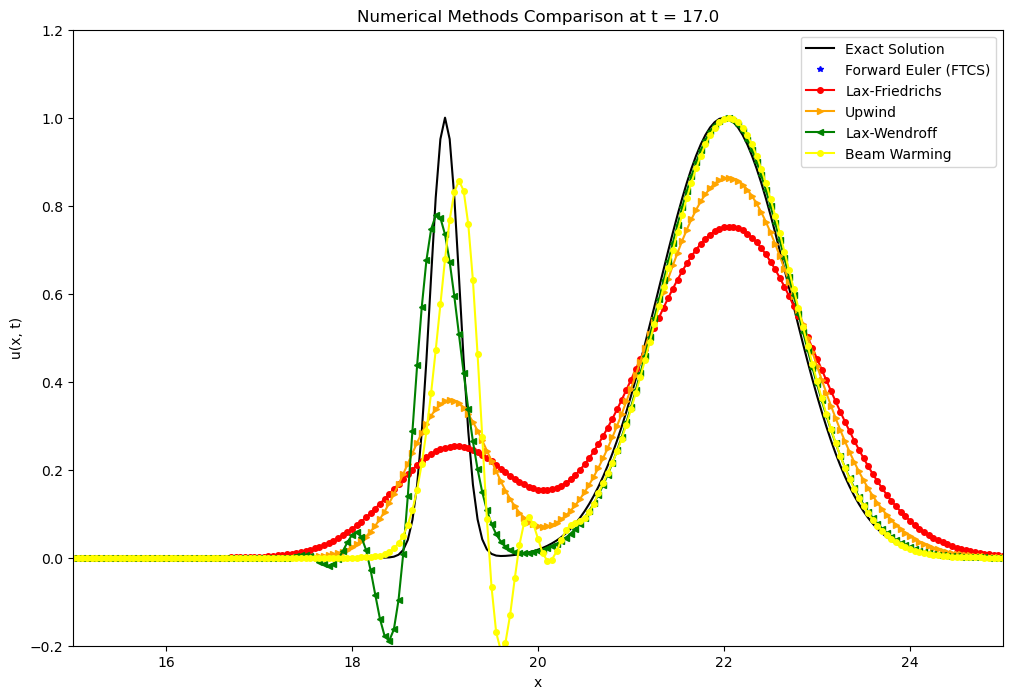

In [149]:

# --- 4. Plotting ---
fig = plt.figure(figsize=(12, 8))
axes = fig.add_subplot(1, 1, 1)

# Plot the exact solution
axes.plot(x, u_true(x, t_final), 'k', label='Exact Solution')

# Plot your numerical solutions
axes.plot(x, U_fe, label='Forward Euler (FTCS)', color = "blue", linestyle = "None" ,marker = "*", markersize=4)
axes.plot(x, U_lax_friedrichs, label='Lax-Friedrichs', color = "red", marker = "o", markersize=4)
axes.plot(x, U_upwind, label='Upwind', color = "orange", marker = ">", markersize=4)
axes.plot(x, U_lax_wendroff, label='Lax-Wendroff', color = "green", marker = "<", markersize=4)
axes.plot(x, U_beam_warming, label='Beam Warming', color = "yellow", marker = "o", markersize=4)

# Set limits and labels
axes.set_xlim((15.0, 25.0))
axes.set_ylim((-0.2, 1.2))
axes.set_xlabel('x')
axes.set_ylabel('u(x, t)')
axes.set_title(f'Numerical Methods Comparison at t = {t_final:.1f}')
axes.legend()

plt.show()

As Forward Euler does not appear, an we know that the method is unstable because of the theory, we are going to plot it independently. We are going to plot in a logarithmic scale the positive and negative parts to also see the oscillatory behaviour.

Aprox values are between -2.1414651892488284e+38 and 2.9088484014437845e+38


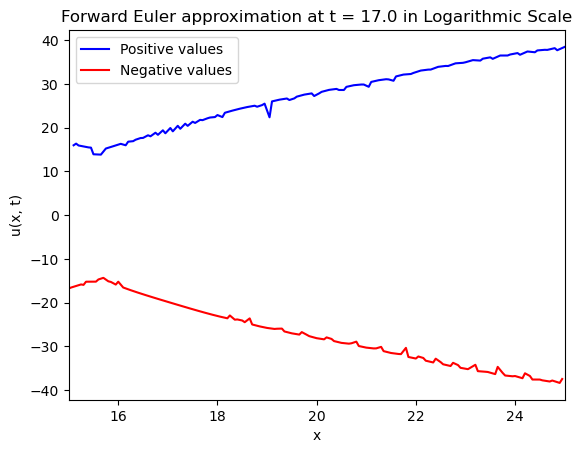

In [156]:

# Nos limitamos al intervalo

x_interval = x[x>=15]
U_fe_interval = U_fe[x>=15]
min_U = min(U_fe_interval)
max_U = max(U_fe_interval)

# Vemos si efectivamente oscila
print(f"Aprox values are between {min_U} and {max_U}")

# Máscaras booleanas para distinguir las partes positiva y negativa
positive = U_fe_interval > 0
negative = U_fe_interval < 0

plt.plot(x_interval[positive], np.log10(U_fe_interval[positive]),
           label='Positive values', color = "blue", marker = "None")

plt.plot(x_interval[negative], -np.log10(-U_fe_interval[negative]),
           label='Negative values', color = "red", marker = "None")

# Set limits and labels
plt.xlim((15.0, 25.0))
plt.xlabel('x')
plt.ylabel('u(x, t)')
plt.title(f'Forward Euler approximation at t = {t_final:.1f} in Logarithmic Scale')
plt.legend()

plt.show()